## Evaluasi Kinerja CNN untuk Klasifikasi Multi-Kelas Tumor Otak pada Citra MRI dengan Teknik Fine-Tuning

- **Model dibandingkan:** VGG-16, ResNet-101, GoogLeNet
- **Dataset:** Brain Tumor MRI Classification (Bhuvaji et al., 2020) - Kaggle
- **Kelas:** Glioma, Meningioma, Pituitary, No Tumor

### 1. Import Library & Cek Environment

In [ ]:
import os
import copy
import time
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

print("Torch version :", torch.__version__)
print("CUDA tersedia :", torch.cuda.is_available())

DEVICE = torch.device("cpu") 
print("Device dipakai:", DEVICE)

Torch version : 2.11.0+cpu
CUDA tersedia : False
Device dipakai: cpu


In [28]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

### 2. Eksplorasi data (lihat struktur folder, jumlah gambar, distribusi kelas, contoh gambar)

In [29]:
DATA_DIR = "dataset" 
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Testing")

print("Isi folder Training:", os.listdir(TRAIN_DIR))
print("Isi folder Testing :", os.listdir(TEST_DIR))

Isi folder Training: ['glioma', 'meningioma', 'notumor', 'pituitary']
Isi folder Testing : ['glioma', 'meningioma', 'notumor', 'pituitary']


#### 2.1 Hitung jumlah gambar per kelas (cek keseimbangan data)

In [30]:
def count_images_per_class(folder_path):
    counts = {}
    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            n_images = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
            counts[class_name] = n_images
    return counts

train_counts = count_images_per_class(TRAIN_DIR)
test_counts = count_images_per_class(TEST_DIR)

df_counts = pd.DataFrame({
    "Training": train_counts,
    "Testing": test_counts
}).fillna(0).astype(int)
df_counts["Total"] = df_counts["Training"] + df_counts["Testing"]
df_counts.loc["TOTAL"] = df_counts.sum()
df_counts

,Training,Testing,Total
glioma,1400,400,1800
meningioma,1400,400,1800
notumor,1400,400,1800
pituitary,1400,400,1800
TOTAL,5600,1600,7200


#### 2.2 Persentase distribusi tiap kelas

            Jumlah Gambar  Persentase (%)
glioma               1800            25.0
meningioma           1800            25.0
notumor              1800            25.0
pituitary            1800            25.0


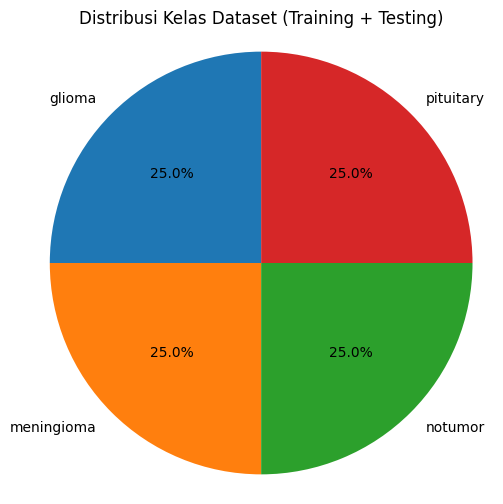

In [31]:
class_only = df_counts.drop(index="TOTAL")["Total"]
percentages = (class_only / class_only.sum() * 100).round(2)

df_pct = pd.DataFrame({
    "Jumlah Gambar": class_only,
    "Persentase (%)": percentages
})
print(df_pct)

plt.figure(figsize=(6, 6))
plt.pie(class_only, labels=class_only.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribusi Kelas Dataset (Training + Testing)")
plt.axis("equal")
plt.show()

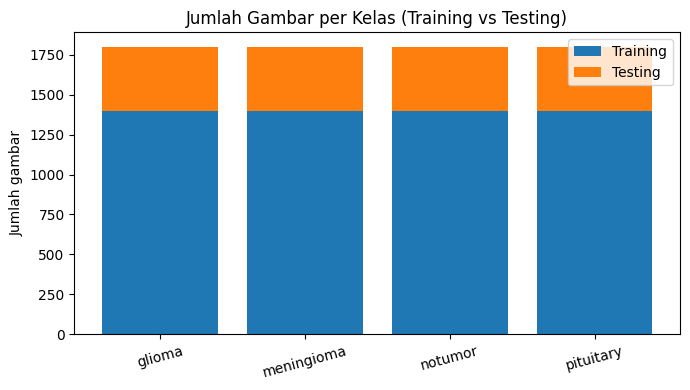

In [32]:
plt.figure(figsize=(7, 4))
plt.bar(df_counts.index[:-1], df_counts["Training"][:-1], label="Training")
plt.bar(df_counts.index[:-1], df_counts["Testing"][:-1],
        bottom=df_counts["Training"][:-1], label="Testing")
plt.ylabel("Jumlah gambar")
plt.title("Jumlah Gambar per Kelas (Training vs Testing)")
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### 2.3 Lihat contoh gambar tiap kelas

Melihat seperti apa citra MRI-nya, apakah grayscale/RGB,
apakah ukurannya bervariasi, apakah ada noise.

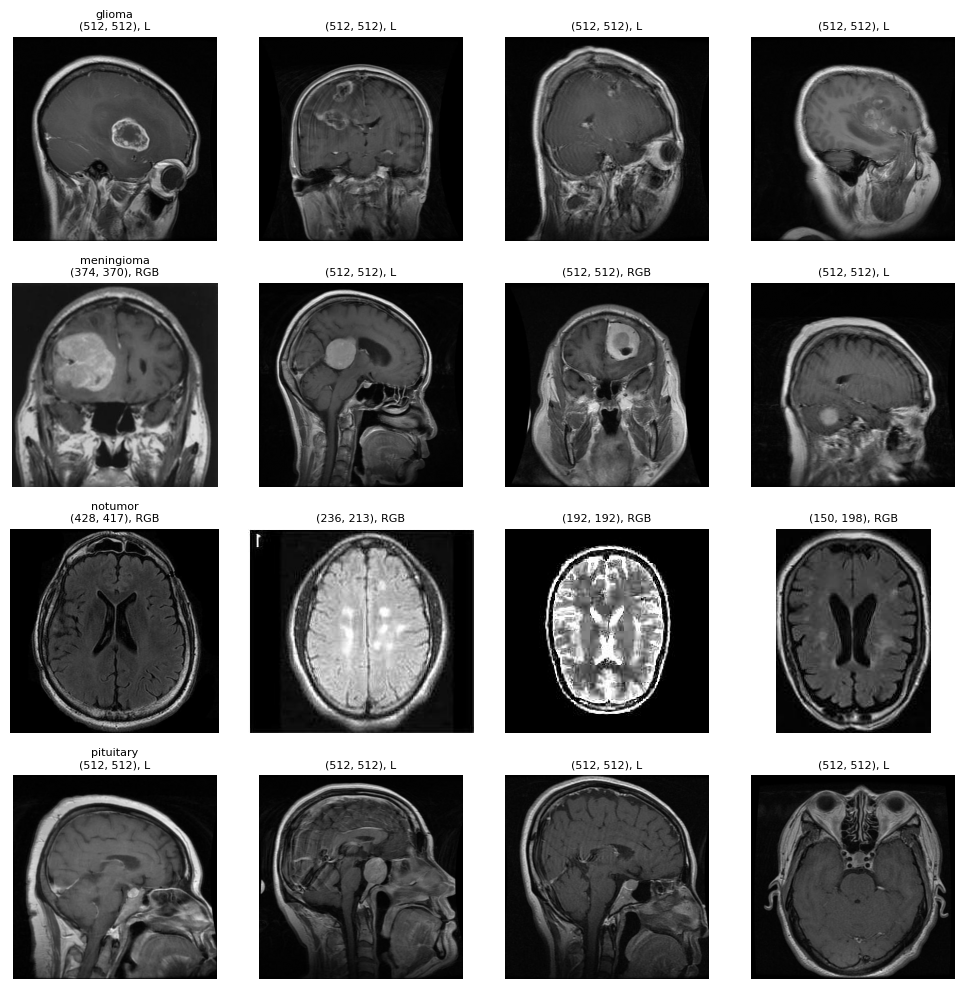

In [33]:
def show_sample_images(folder_path, n_per_class=4):
    class_names = sorted(os.listdir(folder_path))
    fig, axes = plt.subplots(len(class_names), n_per_class,
                              figsize=(n_per_class * 2.5, len(class_names) * 2.5))

    for row, class_name in enumerate(class_names):
        class_path = os.path.join(folder_path, class_name)
        image_files = [f for f in os.listdir(class_path)
                       if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        sample_files = random.sample(image_files, min(n_per_class, len(image_files)))

        for col, fname in enumerate(sample_files):
            img = Image.open(os.path.join(class_path, fname))
            ax = axes[row, col]
            ax.imshow(img, cmap="gray")
            ax.axis("off")
            if col == 0:
                ax.set_ylabel(class_name, fontsize=10)
                ax.set_title(f"{class_name}\n{img.size}, {img.mode}", fontsize=8)
            else:
                ax.set_title(f"{img.size}, {img.mode}", fontsize=8)

    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR, n_per_class=4)

#### 2.4 Cek ukuran & mode warna gambar (untuk menentukan preprocessing)

Kalau ukurannya bervariasi dan mode warnanya campuran (ada yang grayscale `L`,
ada yang RGB), perlu diubah semua jadi ukuran & channel yang seragam
di tahap preprocessing nanti.

In [34]:
sizes = []
modes = []

for class_name in sorted(os.listdir(TRAIN_DIR))[:1]:   # cek 1 kelas dulu sbg sampel cepat
    class_path = os.path.join(TRAIN_DIR, class_name)
    files = os.listdir(class_path)[:200]   # sampel 200 gambar biar cepat
    for fname in files:
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            with Image.open(os.path.join(class_path, fname)) as img:
                sizes.append(img.size)
                modes.append(img.mode)

print("Contoh ukuran gambar (10 pertama):", sizes[:10])
print("Ukuran unik yang ditemukan       :", set(sizes))
print("Mode warna unik yang ditemukan   :", set(modes))

Contoh ukuran gambar (10 pertama): [(512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512)]
Ukuran unik yang ditemukan       : {(512, 512)}
Mode warna unik yang ditemukan   : {'L', 'RGB'}


### 3. Pra-pemrosesan & augmentasi

In [35]:
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),   # paksa 3-channel kalau ada yang grayscale
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),
])

print("Transform siap.")

Transform siap.


#### 3.1 Demonstrasi Efek Augmentasi (Sebelum vs Sesudah)

augmentasi di sini bersifat **on-the-fly / dinamis** artinya augmentasi dilakukan secara acak
setiap kali gambar diambil saat training, **bukan** disimpan sebagai file baru.

Hasil kalau augment on the fly:
- Jumlah file dataset tidak bertambah, tetap sama seperti hasil hitungan di bagian 2.1
- Yang berubah adalah hanya variasi yang dilihat model di epoch 1 gambar A mungkin diputar
  sedikit ke kiri, di epoch 5 gambar A yang sama mungkin di-flip horizontal, dst
- Beda dengan "augmentasi offline" yang benar-benar menggandakan file ke disk

Sel di bawah ini membuktikan **jumlah dataset tetap sama**, dan menunjukkan
seperti apa variasi visual yang dihasilkan augmentasi dari 1 gambar yang sama.

In [57]:
# Jumlah dataset sebelum didefinisikan transform augmentasi
n_before = sum(
    len([f for f in os.listdir(os.path.join(TRAIN_DIR, c))
         if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    for c in os.listdir(TRAIN_DIR)
)

# Jumlah dataset sesudah transform augmentasi terpasang (pakai train_transform)
dataset_with_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
n_after = len(dataset_with_aug)

print(f"Jumlah gambar training SEBELUM augmentasi terpasang : {n_before}")
print(f"Jumlah gambar training SESUDAH augmentasi terpasang : {n_after}")
print(f"Selisih                                             : {n_after - n_before}")
print("\n-> Jumlahnya SAMA. Augmentasi dinamis tidak menambah jumlah data,")
print("   hanya menambah variasi tampilan pada gambar yang sama tiap epoch.")

Jumlah gambar training SEBELUM augmentasi terpasang : 5600
Jumlah gambar training SESUDAH augmentasi terpasang : 5600
Selisih                                             : 0

-> Jumlahnya SAMA. Augmentasi dinamis tidak menambah jumlah data,
   hanya menambah variasi tampilan pada gambar yang sama tiap epoch.


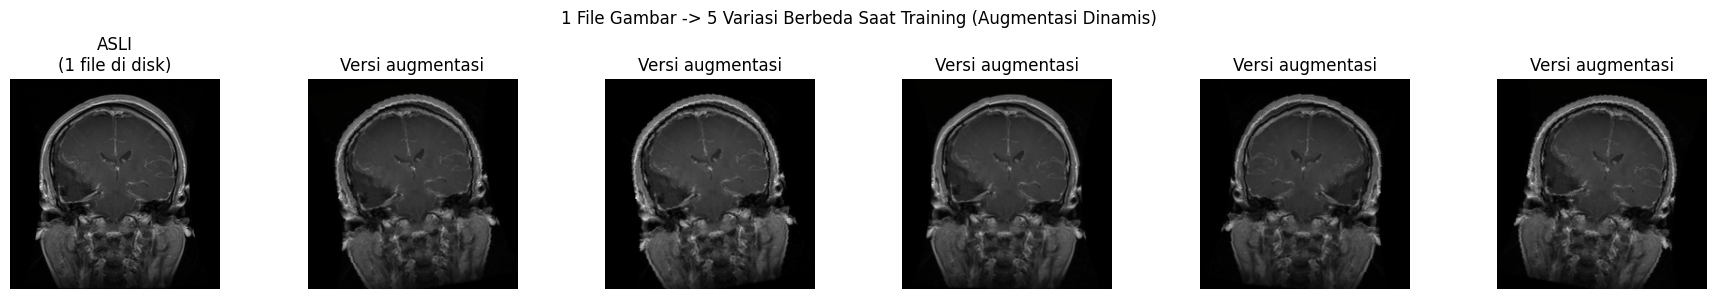


Kesimpulan: dari 1 file 'Tr-gl_1.jpg', dihasilkan 5 tampilan
berbeda di atas -- tapi semuanya berasal dari file yang SAMA, bukan file baru.


In [ ]:
# Ambil 1 file gambar asli sebagai contoh
sample_class = sorted(os.listdir(TRAIN_DIR))[0]
sample_class_path = os.path.join(TRAIN_DIR, sample_class)
sample_file = [f for f in os.listdir(sample_class_path)
               if f.lower().endswith((".jpg", ".jpeg", ".png"))][0]
sample_path = os.path.join(sample_class_path, sample_file)

original_img = Image.open(sample_path)

n_versions = 5
fig, axes = plt.subplots(1, n_versions + 1, figsize=(3 * (n_versions + 1), 3))

# Tampilkan gambar asli (tanpa augmentasi) di kolom pertama
axes[0].imshow(original_img, cmap="gray")
axes[0].set_title("ASLI\n(1 file di disk)")
axes[0].axis("off")

# Tampilkan beberapa hasil augmentasi dari file yang sama
for i in range(1, n_versions + 1):
    augmented_tensor = train_transform(original_img)
    # un-normalize supaya bisa ditampilkan dengan warna wajar
    img_show = augmented_tensor.permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_show = std * img_show + mean
    img_show = np.clip(img_show, 0, 1)

    axes[i].imshow(img_show)
    axes[i].set_title(f"Versi augmentasi")
    axes[i].axis("off")

plt.suptitle(f"1 File Gambar -> {n_versions} Variasi Berbeda Saat Training (Augmentasi Dinamis)")
plt.tight_layout()
plt.show()

print(f"\nKesimpulan: dari 1 file '{sample_file}', dihasilkan {n_versions} tampilan")
print("berbeda di atas -- tapi semuanya berasal dari file yang SAMA, bukan file baru.")

### 4. Split data (Train/Val/Test)

In [ ]:
BATCH_SIZE = 32

# Load kedua folder tanpa transform dulu (transform akan di-apply belakangan,
# beda subset butuh transform berbeda: train pakai augmentasi, val/test tidak)
train_folder_raw = datasets.ImageFolder(TRAIN_DIR, transform=None)
test_folder_raw = datasets.ImageFolder(TEST_DIR, transform=None)

class_names = train_folder_raw.classes
print("Kelas terdeteksi (urutan index):", class_names)
assert train_folder_raw.classes == test_folder_raw.classes, \
    "Urutan kelas di folder Training dan Testing harus sama persis!"

# Gabungkan jadi satu pool besar
combined_dataset = torch.utils.data.ConcatDataset([train_folder_raw, test_folder_raw])
n_total = len(combined_dataset)
print(f"Total seluruh gambar (Training + Testing digabung): {n_total}")

Kelas terdeteksi (urutan index): ['glioma', 'meningioma', 'notumor', 'pituitary']
Total seluruh gambar (Training + Testing digabung): 7200


#### 4.1 Wrapper Dataset untuk Apply Transform Sesuai Subset

In [39]:
class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, label = self.base_dataset[self.indices[idx]]
        if self.transform is not None:
            img = self.transform(img)
        return img, label

print("TransformSubset siap.")

TransformSubset siap.


#### 4.2 Split Index 80:10:10 dari Pool Gabungan

In [40]:
n_train = int(0.80 * n_total)
n_val = int(0.10 * n_total)
n_test = n_total - n_train - n_val   # sisa, biar totalnya pas

generator = torch.Generator().manual_seed(SEED)
all_indices = torch.randperm(n_total, generator=generator).tolist()

train_indices = all_indices[:n_train]
val_indices = all_indices[n_train:n_train + n_val]
test_indices = all_indices[n_train + n_val:]

train_dataset = TransformSubset(combined_dataset, train_indices, train_transform)
val_dataset = TransformSubset(combined_dataset, val_indices, eval_transform)
test_dataset = TransformSubset(combined_dataset, test_indices, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Jumlah data train : {len(train_dataset)} ({len(train_dataset)/n_total*100:.1f}%)")
print(f"Jumlah data val   : {len(val_dataset)} ({len(val_dataset)/n_total*100:.1f}%)")
print(f"Jumlah data test  : {len(test_dataset)} ({len(test_dataset)/n_total*100:.1f}%)")
print(f"Total             : {len(train_dataset) + len(val_dataset) + len(test_dataset)} (harus = {n_total})")

Jumlah data train : 5760 (80.0%)
Jumlah data val   : 720 (10.0%)
Jumlah data test  : 720 (10.0%)
Total             : 7200 (harus = 7200)


In [41]:
# Cek 1 batch untuk memastikan loader berjalan benar
images, labels = next(iter(train_loader))
print("Shape 1 batch gambar:", images.shape)   # [batch, channel, H, W]
print("Shape 1 batch label :", labels.shape)
print("Contoh label       :", labels[:10].tolist())

Shape 1 batch gambar: torch.Size([32, 3, 224, 224])
Shape 1 batch label : torch.Size([32])
Contoh label       : [1, 1, 3, 0, 3, 0, 1, 3, 2, 2]


### 5. Bangun model (transfer learning)

In [42]:
NUM_CLASSES = len(class_names)

def build_model(arch: str, num_classes: int = NUM_CLASSES):
    if arch == "vgg16":
        model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        in_features = model.classifier[6].in_features
        model.classifier[6] = nn.Linear(in_features, num_classes)

    elif arch == "resnet101":
        model = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V2)
        for p in model.parameters():
            p.requires_grad = False
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    elif arch == "googlenet":
        model = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1)
        model.aux_logits = False
        model.aux1 = None
        model.aux2 = None
        for p in model.parameters():
            p.requires_grad = False
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")

    return model.to(DEVICE)


def unfreeze_deep_layers(model, arch: str):
    """Buka lapisan konvolusi terdalam untuk tahap fine-tuning."""
    if arch == "vgg16":
        for name, p in model.named_parameters():
            if name.startswith("features.24") or name.startswith("features.26") \
               or name.startswith("features.28") or name.startswith("classifier"):
                p.requires_grad = True
    elif arch == "resnet101":
        for name, p in model.named_parameters():
            if name.startswith("layer4") or name.startswith("fc"):
                p.requires_grad = True
    elif arch == "googlenet":
        for name, p in model.named_parameters():
            if name.startswith("inception5") or name.startswith("fc"):
                p.requires_grad = True
    return model

print("Fungsi build_model & unfreeze_deep_layers siap.")

Fungsi build_model & unfreeze_deep_layers siap.


#### 5.1 Coba bangun 1 model dulu untuk memastikan tidak ada error (pakai VGG-16)

In [43]:
test_model = build_model("vgg16")
n_trainable = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
n_total_params = sum(p.numel() for p in test_model.parameters())
print(f"Total parameter        : {n_total_params:,}")
print(f"Trainable (sebelum FT) : {n_trainable:,}")

del test_model   # bebaskan memori, model asli akan dibangun ulang di loop training

Total parameter        : 134,276,932
Trainable (sebelum FT) : 16,388


### 6. Fungsi training, evaluasi, plotting

In [44]:
EARLY_STOP_PATIENCE = 5
MAX_EPOCHS = 50   # early stopping akan menghentikan lebih awal kalau tidak ada perbaikan

def train_model(model, train_loader, val_loader, lr, max_epochs, patience, stage_name=""):
    criterion = nn.CrossEntropyLoss()
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(trainable_params, lr=lr)

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, max_epochs + 1):
        t0 = time.time()

        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        elapsed = time.time() - t0
        print(f"[{stage_name}] Epoch {epoch:02d} | train_loss={train_loss:.4f} "
              f"| val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | {elapsed:.1f}s")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"[{stage_name}] Early stopping di epoch {epoch}.")
                break

    model.load_state_dict(best_state)
    return model, history

In [45]:
def evaluate_model(model, test_loader, class_names, stage_name=""):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(DEVICE)
            outputs = model(inputs)
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average="macro", zero_division=0)
    rec = recall_score(all_labels, all_preds, average="macro", zero_division=0)
    f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)

    print(f"\n===== HASIL EVALUASI [{stage_name}] =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}\n")
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(5, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix - {stage_name}")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=45)
    plt.yticks(range(len(class_names)), class_names)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.ylabel("Label Asli")
    plt.xlabel("Label Prediksi")
    plt.tight_layout()
    plt.show()

    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

In [46]:
def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["val_loss"], label="Val Loss")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["val_acc"], label="Val Accuracy", color="green")
    axes[1].set_title(f"Val Accuracy - {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### 7. Fungsi pipeline per arsitektur

In [47]:
def run_pipeline(arch, train_loader, val_loader, test_loader, class_names):
    print(f"\n{'='*60}\nARSITEKTUR: {arch.upper()}\n{'='*60}")
    model = build_model(arch)

    print(">>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)")
    model, hist_before = train_model(
        model, train_loader, val_loader,
        lr=1e-3, max_epochs=MAX_EPOCHS, patience=EARLY_STOP_PATIENCE,
        stage_name=f"{arch}-before-FT"
    )
    plot_history(hist_before, title=f"{arch} - Sebelum Fine-Tuning")
    metrics_before = evaluate_model(model, test_loader, class_names, stage_name=f"{arch} - Sebelum FT")

    print(">>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)")
    model = unfreeze_deep_layers(model, arch)
    n_trainable_ft = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable parameter setelah unfreeze: {n_trainable_ft:,}")

    model, hist_ft = train_model(
        model, train_loader, val_loader,
        lr=1e-4, max_epochs=MAX_EPOCHS, patience=EARLY_STOP_PATIENCE,
        stage_name=f"{arch}-fine-tuning"
    )
    plot_history(hist_ft, title=f"{arch} - Fine-Tuning")
    metrics_after = evaluate_model(model, test_loader, class_names, stage_name=f"{arch} - Sesudah FT")

    print(f"\nRingkasan {arch}:")
    print(f"  Sebelum FT -> F1: {metrics_before['f1']:.4f}, Accuracy: {metrics_before['accuracy']:.4f}")
    print(f"  Sesudah FT -> F1: {metrics_after['f1']:.4f}, Accuracy: {metrics_after['accuracy']:.4f}")
    print(f"  Peningkatan F1  : {metrics_after['f1'] - metrics_before['f1']:+.4f}")

    os.makedirs("results", exist_ok=True)
    torch.save(model.state_dict(), f"results/{arch}_finetuned.pth")
    with open(f"results/{arch}_metrics.json", "w") as f:
        json.dump({"before": metrics_before, "after": metrics_after}, f, indent=2)

    return {"arch": arch, "before": metrics_before, "after": metrics_after,
            "hist_before": hist_before, "hist_ft": hist_ft}

all_results = []   # akan diisi bertahap oleh tiap arsitektur di bawah

### 8. Jalankan VGG-16


ARSITEKTUR: VGG16
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[vgg16-before-FT] Epoch 01 | train_loss=0.6751 | val_loss=0.4658 | val_acc=0.8319 | 985.5s
[vgg16-before-FT] Epoch 02 | train_loss=0.5428 | val_loss=0.4590 | val_acc=0.8236 | 993.9s
[vgg16-before-FT] Epoch 03 | train_loss=0.5151 | val_loss=0.4707 | val_acc=0.8181 | 1047.6s
[vgg16-before-FT] Epoch 04 | train_loss=0.5160 | val_loss=0.4208 | val_acc=0.8431 | 912.9s
[vgg16-before-FT] Epoch 05 | train_loss=0.5113 | val_loss=0.4073 | val_acc=0.8500 | 954.6s
[vgg16-before-FT] Epoch 06 | train_loss=0.5060 | val_loss=0.3902 | val_acc=0.8500 | 923.3s
[vgg16-before-FT] Epoch 07 | train_loss=0.5049 | val_loss=0.4770 | val_acc=0.8181 | 928.4s
[vgg16-before-FT] Epoch 08 | train_loss=0.5391 | val_loss=0.4043 | val_acc=0.8556 | 899.8s
[vgg16-before-FT] Epoch 09 | train_loss=0.5074 | val_loss=0.3936 | val_acc=0.8514 | 908.4s
[vgg16-before-FT] Epoch 10 | train_loss=0.5008 | val_loss=0.3682 | val_acc=0.8736 | 893.0s
[vgg1

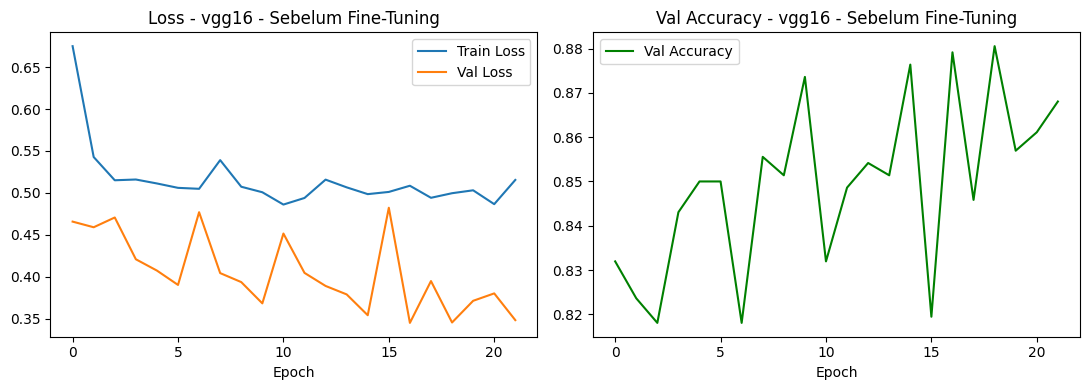


===== HASIL EVALUASI [vgg16 - Sebelum FT] =====
Accuracy : 0.8792
Precision: 0.8834
Recall   : 0.8826
F1-Score : 0.8821

              precision    recall  f1-score   support

      glioma       0.92      0.83      0.87       195
  meningioma       0.77      0.83      0.80       181
     notumor       0.96      0.97      0.96       160
   pituitary       0.88      0.90      0.89       184

    accuracy                           0.88       720
   macro avg       0.88      0.88      0.88       720
weighted avg       0.88      0.88      0.88       720



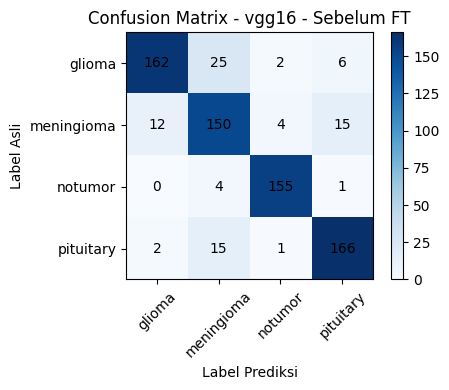

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 126,641,668
[vgg16-fine-tuning] Epoch 01 | train_loss=0.3816 | val_loss=0.2295 | val_acc=0.9236 | 1067.9s
[vgg16-fine-tuning] Epoch 02 | train_loss=0.1918 | val_loss=0.3848 | val_acc=0.8792 | 1039.1s
[vgg16-fine-tuning] Epoch 03 | train_loss=0.1324 | val_loss=0.1510 | val_acc=0.9500 | 1088.8s
[vgg16-fine-tuning] Epoch 04 | train_loss=0.0893 | val_loss=0.1829 | val_acc=0.9500 | 1221.0s
[vgg16-fine-tuning] Epoch 05 | train_loss=0.0825 | val_loss=0.2098 | val_acc=0.9611 | 1222.5s
[vgg16-fine-tuning] Epoch 06 | train_loss=0.0606 | val_loss=0.1606 | val_acc=0.9528 | 1164.6s
[vgg16-fine-tuning] Epoch 07 | train_loss=0.0736 | val_loss=0.3100 | val_acc=0.9458 | 1244.0s
[vgg16-fine-tuning] Epoch 08 | train_loss=0.0573 | val_loss=0.2504 | val_acc=0.9583 | 1160.7s
[vgg16-fine-tuning] Early stopping di epoch 8.


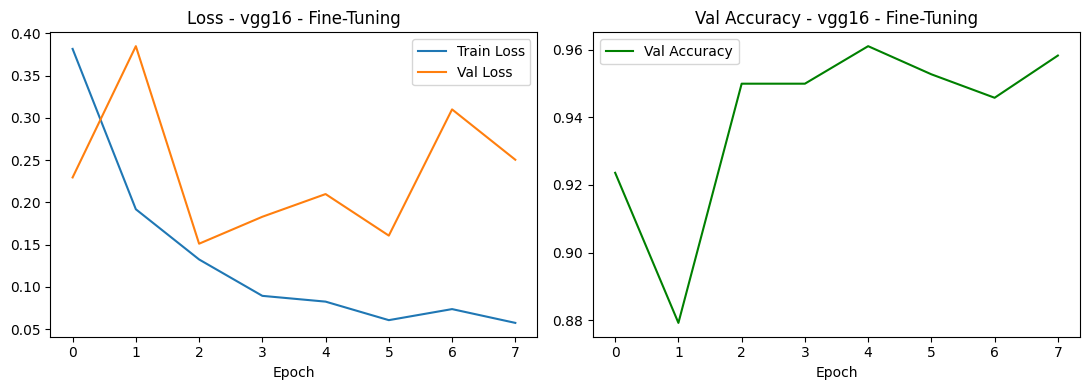


===== HASIL EVALUASI [vgg16 - Sesudah FT] =====
Accuracy : 0.9528
Precision: 0.9539
Recall   : 0.9537
F1-Score : 0.9537

              precision    recall  f1-score   support

      glioma       0.93      0.95      0.94       195
  meningioma       0.92      0.91      0.91       181
     notumor       0.98      0.99      0.98       160
   pituitary       0.99      0.96      0.98       184

    accuracy                           0.95       720
   macro avg       0.95      0.95      0.95       720
weighted avg       0.95      0.95      0.95       720



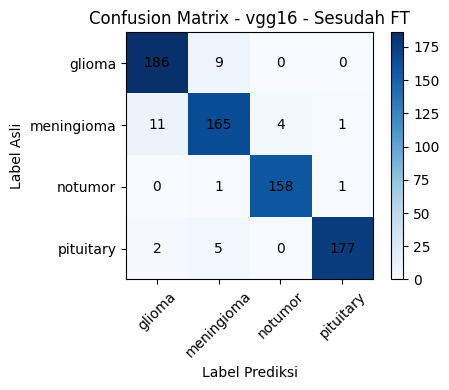


Ringkasan vgg16:
  Sebelum FT -> F1: 0.8821, Accuracy: 0.8792
  Sesudah FT -> F1: 0.9537, Accuracy: 0.9528
  Peningkatan F1  : +0.0716


In [25]:
result_vgg16 = run_pipeline("vgg16", train_loader, val_loader, test_loader, class_names)
all_results.append(result_vgg16)

### 9. Jalankan ResNet-101


ARSITEKTUR: RESNET101
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[resnet101-before-FT] Epoch 01 | train_loss=0.7093 | val_loss=0.6046 | val_acc=0.8347 | 716.1s
[resnet101-before-FT] Epoch 02 | train_loss=0.4741 | val_loss=0.5088 | val_acc=0.8556 | 691.3s
[resnet101-before-FT] Epoch 03 | train_loss=0.4166 | val_loss=0.4786 | val_acc=0.8569 | 609.6s
[resnet101-before-FT] Epoch 04 | train_loss=0.3834 | val_loss=0.4739 | val_acc=0.8792 | 557.4s
[resnet101-before-FT] Epoch 05 | train_loss=0.3698 | val_loss=0.4354 | val_acc=0.8750 | 545.0s
[resnet101-before-FT] Epoch 06 | train_loss=0.3530 | val_loss=0.4485 | val_acc=0.8792 | 552.5s
[resnet101-before-FT] Epoch 07 | train_loss=0.3350 | val_loss=0.4333 | val_acc=0.8806 | 551.9s
[resnet101-before-FT] Epoch 08 | train_loss=0.3206 | val_loss=0.4694 | val_acc=0.8861 | 549.2s
[resnet101-before-FT] Epoch 09 | train_loss=0.3234 | val_loss=0.3745 | val_acc=0.8931 | 550.4s
[resnet101-before-FT] Epoch 10 | train_loss=0.3129 | val_

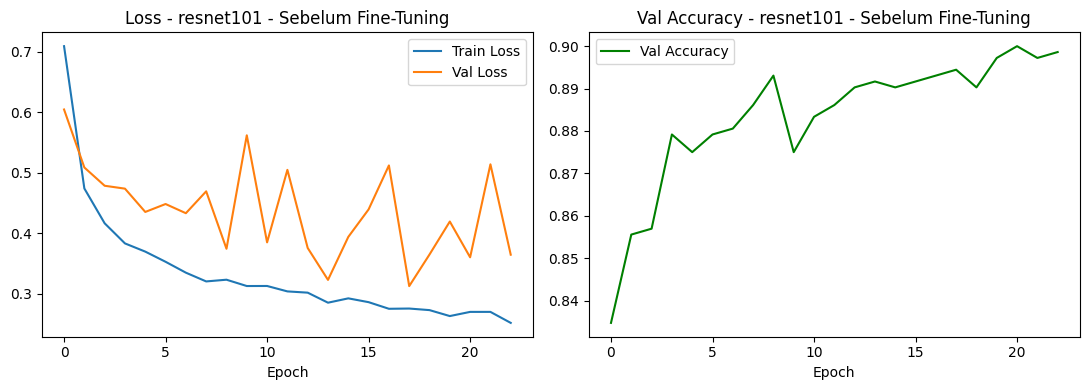


===== HASIL EVALUASI [resnet101 - Sebelum FT] =====
Accuracy : 0.8819
Precision: 0.8814
Recall   : 0.8849
F1-Score : 0.8816

              precision    recall  f1-score   support

      glioma       0.93      0.84      0.88       195
  meningioma       0.82      0.77      0.79       181
     notumor       0.90      0.97      0.93       160
   pituitary       0.88      0.96      0.92       184

    accuracy                           0.88       720
   macro avg       0.88      0.88      0.88       720
weighted avg       0.88      0.88      0.88       720



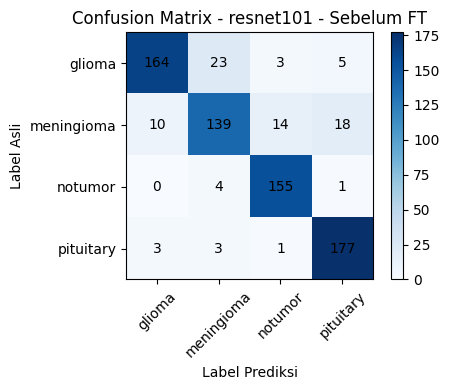

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 14,972,932
[resnet101-fine-tuning] Epoch 01 | train_loss=0.2495 | val_loss=0.4544 | val_acc=0.9111 | 619.3s
[resnet101-fine-tuning] Epoch 02 | train_loss=0.1547 | val_loss=0.2816 | val_acc=0.9333 | 614.7s
[resnet101-fine-tuning] Epoch 03 | train_loss=0.1104 | val_loss=0.3651 | val_acc=0.9417 | 619.1s
[resnet101-fine-tuning] Epoch 04 | train_loss=0.0848 | val_loss=0.3297 | val_acc=0.9431 | 618.0s
[resnet101-fine-tuning] Epoch 05 | train_loss=0.0705 | val_loss=0.1786 | val_acc=0.9528 | 617.3s
[resnet101-fine-tuning] Epoch 06 | train_loss=0.0540 | val_loss=0.1860 | val_acc=0.9458 | 621.8s
[resnet101-fine-tuning] Epoch 07 | train_loss=0.0540 | val_loss=0.1778 | val_acc=0.9569 | 619.8s
[resnet101-fine-tuning] Epoch 08 | train_loss=0.0493 | val_loss=0.2285 | val_acc=0.9583 | 624.4s
[resnet101-fine-tuning] Epoch 09 | train_loss=0.0375 | val_loss=0.1948 | val_acc=0.9597 | 618.0s
[resnet101-fine-t

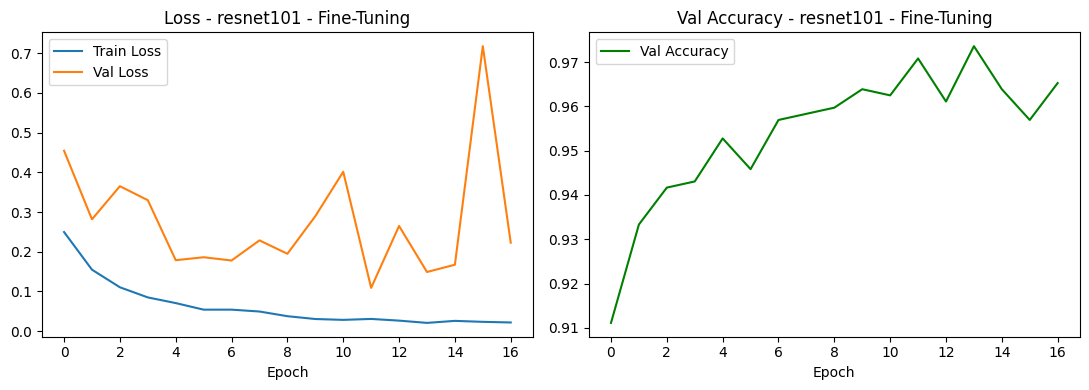


===== HASIL EVALUASI [resnet101 - Sesudah FT] =====
Accuracy : 0.9764
Precision: 0.9770
Recall   : 0.9763
F1-Score : 0.9765

              precision    recall  f1-score   support

      glioma       0.97      0.98      0.98       195
  meningioma       0.98      0.94      0.96       181
     notumor       0.99      0.98      0.98       160
   pituitary       0.97      1.00      0.98       184

    accuracy                           0.98       720
   macro avg       0.98      0.98      0.98       720
weighted avg       0.98      0.98      0.98       720



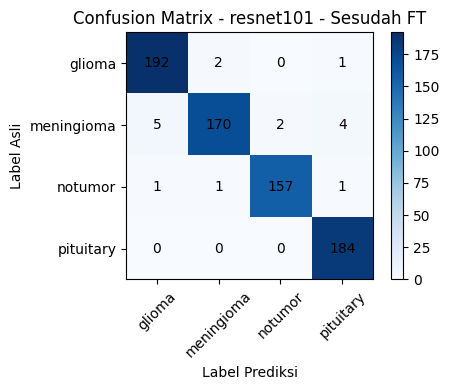


Ringkasan resnet101:
  Sebelum FT -> F1: 0.8816, Accuracy: 0.8819
  Sesudah FT -> F1: 0.9765, Accuracy: 0.9764
  Peningkatan F1  : +0.0949


In [26]:
result_resnet101 = run_pipeline("resnet101", train_loader, val_loader, test_loader, class_names)
all_results.append(result_resnet101)

### 10. Jalankan GoogLeNet


ARSITEKTUR: GOOGLENET
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[googlenet-before-FT] Epoch 01 | train_loss=0.7721 | val_loss=0.5809 | val_acc=0.8083 | 608.2s
[googlenet-before-FT] Epoch 02 | train_loss=0.5415 | val_loss=0.4891 | val_acc=0.8403 | 568.2s
[googlenet-before-FT] Epoch 03 | train_loss=0.4909 | val_loss=0.4422 | val_acc=0.8583 | 563.0s
[googlenet-before-FT] Epoch 04 | train_loss=0.4605 | val_loss=0.4347 | val_acc=0.8583 | 571.7s
[googlenet-before-FT] Epoch 05 | train_loss=0.4446 | val_loss=0.4020 | val_acc=0.8653 | 595.9s
[googlenet-before-FT] Epoch 06 | train_loss=0.4413 | val_loss=0.3979 | val_acc=0.8639 | 550.7s
[googlenet-before-FT] Epoch 07 | train_loss=0.4160 | val_loss=0.3847 | val_acc=0.8681 | 558.4s
[googlenet-before-FT] Epoch 08 | train_loss=0.4321 | val_loss=0.3755 | val_acc=0.8722 | 553.5s
[googlenet-before-FT] Epoch 09 | train_loss=0.4178 | val_loss=0.3874 | val_acc=0.8778 | 565.4s
[googlenet-before-FT] Epoch 10 | train_loss=0.4043 | val_

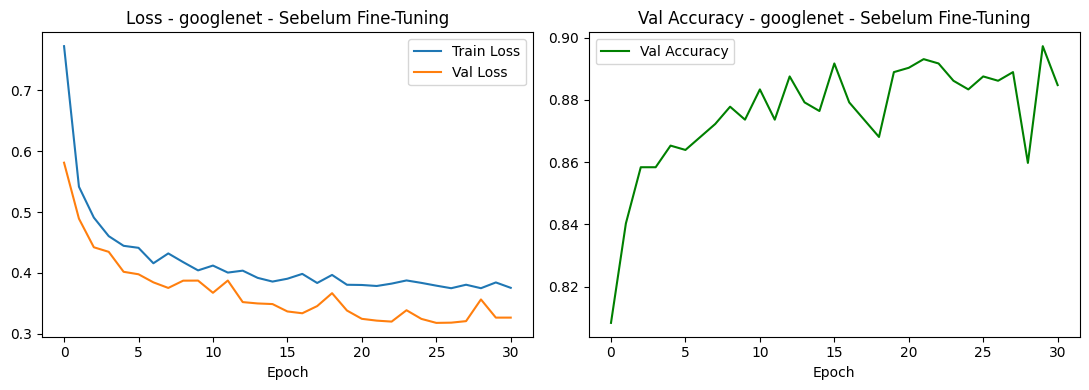


===== HASIL EVALUASI [googlenet - Sebelum FT] =====
Accuracy : 0.8847
Precision: 0.8845
Recall   : 0.8880
F1-Score : 0.8850

              precision    recall  f1-score   support

      glioma       0.92      0.84      0.87       195
  meningioma       0.82      0.78      0.80       181
     notumor       0.92      0.97      0.95       160
   pituitary       0.89      0.96      0.92       184

    accuracy                           0.88       720
   macro avg       0.88      0.89      0.89       720
weighted avg       0.88      0.88      0.88       720



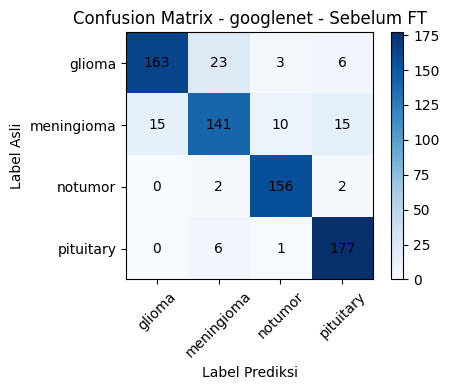

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 2,330,084
[googlenet-fine-tuning] Epoch 01 | train_loss=0.3168 | val_loss=0.2158 | val_acc=0.9250 | 635.7s
[googlenet-fine-tuning] Epoch 02 | train_loss=0.2227 | val_loss=0.1729 | val_acc=0.9347 | 650.3s
[googlenet-fine-tuning] Epoch 03 | train_loss=0.1652 | val_loss=0.1580 | val_acc=0.9347 | 712.6s
[googlenet-fine-tuning] Epoch 04 | train_loss=0.1428 | val_loss=0.1288 | val_acc=0.9597 | 631.7s
[googlenet-fine-tuning] Epoch 05 | train_loss=0.1056 | val_loss=0.1231 | val_acc=0.9611 | 631.2s
[googlenet-fine-tuning] Epoch 06 | train_loss=0.0974 | val_loss=0.1214 | val_acc=0.9639 | 637.0s
[googlenet-fine-tuning] Epoch 07 | train_loss=0.0836 | val_loss=0.1208 | val_acc=0.9542 | 629.6s
[googlenet-fine-tuning] Epoch 08 | train_loss=0.0734 | val_loss=0.1059 | val_acc=0.9653 | 622.0s
[googlenet-fine-tuning] Epoch 09 | train_loss=0.0644 | val_loss=0.1036 | val_acc=0.9667 | 623.3s
[googlenet-fine-tu

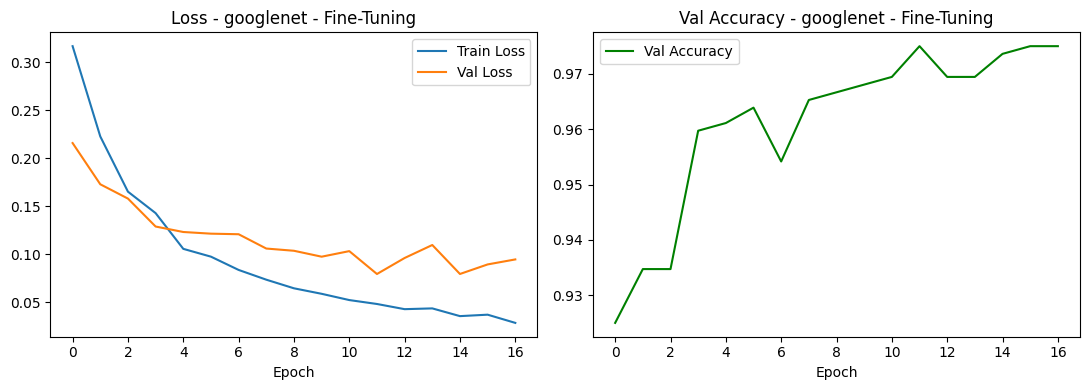


===== HASIL EVALUASI [googlenet - Sesudah FT] =====
Accuracy : 0.9889
Precision: 0.9893
Recall   : 0.9893
F1-Score : 0.9893

              precision    recall  f1-score   support

      glioma       0.98      0.98      0.98       195
  meningioma       0.98      0.98      0.98       181
     notumor       1.00      1.00      1.00       160
   pituitary       0.99      1.00      0.99       184

    accuracy                           0.99       720
   macro avg       0.99      0.99      0.99       720
weighted avg       0.99      0.99      0.99       720



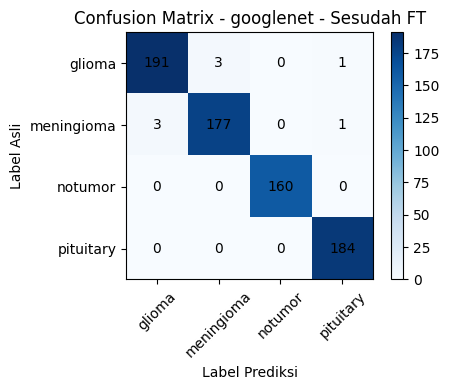


Ringkasan googlenet:
  Sebelum FT -> F1: 0.8850, Accuracy: 0.8847
  Sesudah FT -> F1: 0.9893, Accuracy: 0.9889
  Peningkatan F1  : +0.1043


In [22]:
result_googlenet = run_pipeline("googlenet", train_loader, val_loader, test_loader, class_names)
all_results.append(result_googlenet)

### 11. Bandingkan semua model & visualisasi akhir

In [54]:
import json

all_results = []
for arch in ["vgg16", "resnet101", "googlenet"]:
    with open(f"results/{arch}_metrics.json", "r") as f:
        metrics = json.load(f)
    all_results.append({
        "arch": arch,
        "before": metrics["before"],
        "after": metrics["after"],
    })

print("Berhasil load", len(all_results), "hasil dari file.")

Berhasil load 3 hasil dari file.


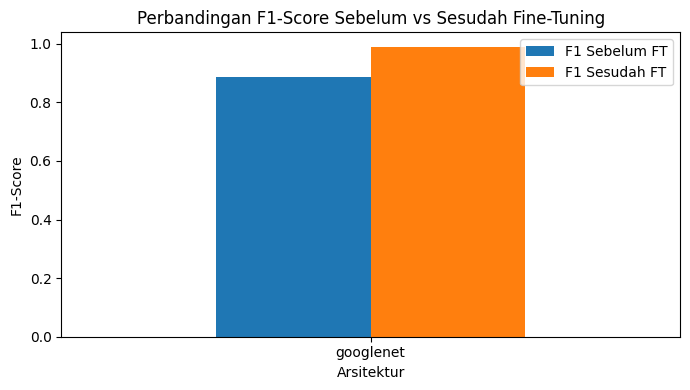

In [53]:
df_summary[["F1 Sebelum FT", "F1 Sesudah FT"]].plot(kind="bar", figsize=(7, 4))
plt.title("Perbandingan F1-Score Sebelum vs Sesudah Fine-Tuning")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:
import json

all_results = []
for arch in ["vgg16", "resnet101", "googlenet"]:
    with open(f"results/{arch}_metrics.json", "r", encoding="utf-8") as f:
        metrics = json.load(f)
    all_results.append({
        "arch": arch,
        "before": metrics["before"],
        "after": metrics["after"],
    })

print("Berhasil load", len(all_results), "hasil dari file.")
for r in all_results:
    print(f"  - {r['arch']}")

Berhasil load 3 hasil dari file.
  - vgg16
  - resnet101
  - googlenet


In [56]:
import pandas as pd

summary_rows = []
for r in all_results:
    summary_rows.append({
        "Arsitektur": r["arch"],
        "F1 Sebelum FT": r["before"]["f1"],
        "F1 Sesudah FT": r["after"]["f1"],
        "Peningkatan F1": r["after"]["f1"] - r["before"]["f1"],
        "Accuracy Sebelum FT": r["before"]["accuracy"],
        "Accuracy Sesudah FT": r["after"]["accuracy"],
    })

df_summary = pd.DataFrame(summary_rows).set_index("Arsitektur")
df_summary

,F1 Sebelum FT,F1 Sesudah FT,Peningkatan F1,Accuracy Sebelum FT,Accuracy Sesudah FT
Arsitektur,,,,,
vgg16,0.882130,0.953716,0.071585,0.879167,0.952778
resnet101,0.881604,0.976459,0.094854,0.881944,0.976389
googlenet,0.885048,0.989302,0.104255,0.884722,0.988889
